In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

PROJECT_RANDOM_STATE = 2627
print(f"PROJECT_RANDOM_STATE = {PROJECT_RANDOM_STATE}")
print("BLAS/OpenMP threads limited to 1 for reproducible notebook execution")

PROJECT_RANDOM_STATE = 2627
BLAS/OpenMP threads limited to 1 for reproducible notebook execution


# Practice 3 — Challenge A: Cybersecurity
## P3.1 Multinomial logistic regression, P3.2 parameterisation bridge, and P3.5 comparison

This notebook continues the frozen Practice 2 protocol. It reads the course-owned canonical five-fold assignment, keeps the same eleven source predictors, fits every learned preprocessing object inside each training fold, and evaluates only on the corresponding validation fold.

In [2]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

PROJECT_DIR = Path(".")
CYBER_DIR = PROJECT_DIR / "datos" / "cyber"
CYBER_DEVELOPMENT_FILE = CYBER_DIR / "cyber_development.csv"
CYBER_FOLDS_FILE = CYBER_DIR / "cyber_folds.csv"
CYBER_CLASS_CODES_FILE = CYBER_DIR / "cyber_class_codes.json"
COMPARISON_FILE = PROJECT_DIR / "comparativa.csv"

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


In [3]:
cyber = pd.read_csv(CYBER_DEVELOPMENT_FILE)
folds = pd.read_csv(CYBER_FOLDS_FILE)
with open(CYBER_CLASS_CODES_FILE, "r", encoding="utf-8") as f:
    class_codes = {int(k): v for k, v in json.load(f).items()}

assert folds["row_id"].is_unique
assert set(folds["row_id"]) == set(cyber["row_id"])
cyber = cyber.merge(folds, on="row_id", how="left", validate="one_to_one")
assert set(cyber["fold_id"]) == {0, 1, 2, 3, 4}

NOMINAL_FEATURES = ["proto", "service", "conn_state"]
NUMERIC_FEATURES = ["duration", "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]
MODEL_FEATURES = NOMINAL_FEATURES + NUMERIC_FEATURES
REFERENCE_LEVELS = ["tcp", "-", "SF"]
REFERENCE_LEVEL_BY_PREDICTOR = dict(zip(NOMINAL_FEATURES, REFERENCE_LEVELS))
REFERENCE_CLASS_CODE = 5
REFERENCE_CLASS_NAME = class_codes[REFERENCE_CLASS_CODE]

print("Rows:", len(cyber))
print("Model source predictors:", MODEL_FEATURES)
print("Declared categorical reference levels:", REFERENCE_LEVEL_BY_PREDICTOR)
print("Declared target reference class:", REFERENCE_CLASS_CODE, REFERENCE_CLASS_NAME)

Rows: 34928
Model source predictors: ['proto', 'service', 'conn_state', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes']
Declared categorical reference levels: {'proto': 'tcp', 'service': '-', 'conn_state': 'SF'}
Declared target reference class: 5 normal


## Required interpretation route

The three nominal predictors are one-hot encoded with one declared level dropped per predictor. The references are `proto=tcp`, `service=-`, and `conn_state=SF`: each is a frequent, operationally readable baseline and is present in every canonical training portion. `handle_unknown="ignore"` is declared explicitly; therefore an unseen validation level is encoded as all zeros for that predictor and is treated like the declared reference level.

The eight numeric predictors keep the Practice 2 `log1p` representation and are then standardised inside each fold. This gives them one common coefficient scale without introducing new predictive information. The Cyber logistic fit is explicitly **unpenalised** (`penalty=None`) and uses `class_weight=None` as required.

In [4]:
reference_checks = []
unseen_levels = []
for predictor, reference in REFERENCE_LEVEL_BY_PREDICTOR.items():
    for fold_id in sorted(cyber["fold_id"].unique()):
        training_mask = cyber["fold_id"] != fold_id
        validation_mask = ~training_mask
        reference_checks.append({
            "predictor": predictor,
            "reference_level": reference,
            "fold_id": fold_id,
            "training_count": int((training_mask & (cyber[predictor] == reference)).sum()),
        })
        training_levels = set(cyber.loc[training_mask, predictor].astype(str))
        validation_levels = set(cyber.loc[validation_mask, predictor].astype(str))
        for level in sorted(validation_levels - training_levels):
            unseen_levels.append({
                "fold_id": fold_id,
                "predictor": predictor,
                "unseen_validation_level": level,
                "count": int((validation_mask & (cyber[predictor].astype(str) == level)).sum()),
            })

reference_checks = pd.DataFrame(reference_checks)
unseen_levels = pd.DataFrame(unseen_levels)
assert (reference_checks["training_count"] > 0).all()
display(reference_checks)
print("Unseen validation levels:")
display(unseen_levels if len(unseen_levels) else pd.DataFrame({"result": ["none"]}))

,predictor,reference_level,fold_id,training_count
0,proto,tcp,0,22721
1,proto,tcp,1,22737
2,proto,tcp,2,22729
3,proto,tcp,3,22728
4,proto,tcp,4,22777
5,service,-,0,13152
6,service,-,1,13189
7,service,-,2,13153
8,service,-,3,13146
9,service,-,4,13176


Unseen validation levels:


,fold_id,predictor,unseen_validation_level,count
0,3,service,gssapi,1


In [5]:
def make_cyber_pipeline():
    numeric_preprocessing = Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    preprocessing = ColumnTransformer([
        ("nominal", OneHotEncoder(
            drop=REFERENCE_LEVELS,
            handle_unknown="ignore",
            sparse_output=False,
        ), NOMINAL_FEATURES),
        ("numeric", numeric_preprocessing, NUMERIC_FEATURES),
    ], verbose_feature_names_out=False)

    estimator = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=1000,
        tol=5e-4,
        class_weight=None,
    )
    return Pipeline([
        ("preprocess", preprocessing),
        ("model", estimator),
    ])

# Show the effective settings from the estimator itself.
_effective = make_cyber_pipeline().named_steps["model"].get_params()
display(pd.Series({k: _effective[k] for k in ["penalty", "C", "l1_ratio", "class_weight", "solver", "max_iter", "tol"]}, name="effective value"))

penalty           None
C                  1.0
l1_ratio           0.0
class_weight      None
solver           lbfgs
max_iter          1000
tol             0.0005
Name: effective value, dtype: object

## P3.1 — Multinomial logistic regression on the canonical folds

The five folds are read from `cyber_folds.csv`; they are never reconstructed. The preprocessing pipeline is fitted separately on the four training folds and then applied unchanged to the validation fold. The primary metric is macro F1. Weighted F1 and accuracy are reported as supporting metrics, followed by out-of-fold per-class metrics and a semantic confusion matrix.

In [6]:
class_values = sorted(class_codes)
oof_prediction = np.empty(len(cyber), dtype=int)
fold_rows = []

for fold_id in sorted(cyber["fold_id"].unique()):
    valid_idx = np.flatnonzero(cyber["fold_id"].to_numpy() == fold_id)
    train_idx = np.flatnonzero(cyber["fold_id"].to_numpy() != fold_id)

    model = make_cyber_pipeline()
    start = time.perf_counter()
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=FutureWarning, message=".*penalty.*deprecated.*")
        warnings.filterwarnings("ignore", category=UserWarning, message="Found unknown categories.*")
        model.fit(cyber.iloc[train_idx][MODEL_FEATURES], cyber.iloc[train_idx]["attack_code"])
        prediction = model.predict(cyber.iloc[valid_idx][MODEL_FEATURES])
    fit_time = time.perf_counter() - start

    oof_prediction[valid_idx] = prediction
    y_valid = cyber.iloc[valid_idx]["attack_code"]
    fold_rows.append({
        "fold_id": fold_id,
        "macro_f1": f1_score(y_valid, prediction, average="macro"),
        "weighted_f1": f1_score(y_valid, prediction, average="weighted"),
        "accuracy": accuracy_score(y_valid, prediction),
        "fit_time_s": fit_time,
        "max_iterations_used": int(model.named_steps["model"].n_iter_.max()),
    })

cyber_fold_metrics = pd.DataFrame(fold_rows)
display(cyber_fold_metrics.round(6))
print(f"Mean macro F1: {cyber_fold_metrics['macro_f1'].mean():.6f}")
print(f"Macro F1 range: {(cyber_fold_metrics['macro_f1'].max() - cyber_fold_metrics['macro_f1'].min()):.6f}")
print(f"Macro F1 population SD across folds: {cyber_fold_metrics['macro_f1'].std(ddof=0):.6f}")
print(f"Mean weighted F1: {cyber_fold_metrics['weighted_f1'].mean():.6f}")
print(f"Mean accuracy: {cyber_fold_metrics['accuracy'].mean():.6f}")

,fold_id,macro_f1,weighted_f1,accuracy,fit_time_s,max_iterations_used
0,0,0.828576,0.851319,0.853564,2.145552,333
1,1,0.830937,0.849690,0.851990,2.099181,346
2,2,0.828139,0.844618,0.846958,1.557494,259
3,3,0.823515,0.847303,0.849127,1.563255,245
4,4,0.826429,0.848053,0.849535,2.090084,309


Mean macro F1: 0.827519
Macro F1 range: 0.007422
Macro F1 population SD across folds: 0.002466
Mean weighted F1: 0.848197
Mean accuracy: 0.850235


,class_code,class_name,precision,recall,f1,support
0,0,backdoor,0.806636,0.989193,0.888635,1573
1,1,ddos,0.776189,0.904583,0.835482,4800
2,2,dos,0.810906,0.768333,0.789046,4800
3,3,injection,0.897236,0.913125,0.905111,4800
4,4,mitm,0.633987,0.361491,0.460443,805
5,5,normal,0.794492,0.871458,0.831197,4800
6,6,password,0.957152,0.907500,0.931665,4800
7,7,ransomware,0.933014,0.937500,0.935252,208
8,8,scanning,0.887163,0.854602,0.870578,3542
9,9,xss,0.901865,0.765833,0.828301,4800


,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss
backdoor,1556,2,0,0,6,2,0,0,3,4
ddos,5,4342,13,112,15,40,90,1,24,158
dos,20,93,3688,10,49,637,3,0,290,10
injection,2,234,37,4383,7,27,28,1,3,78
mitm,0,79,70,13,291,270,15,0,38,29
normal,1,36,282,96,43,4183,46,5,20,88
password,343,11,13,2,8,42,4356,0,1,24
ransomware,0,0,3,0,1,3,1,195,0,5
scanning,0,21,420,2,27,40,0,1,3027,4
xss,2,776,22,267,12,21,12,6,6,3676


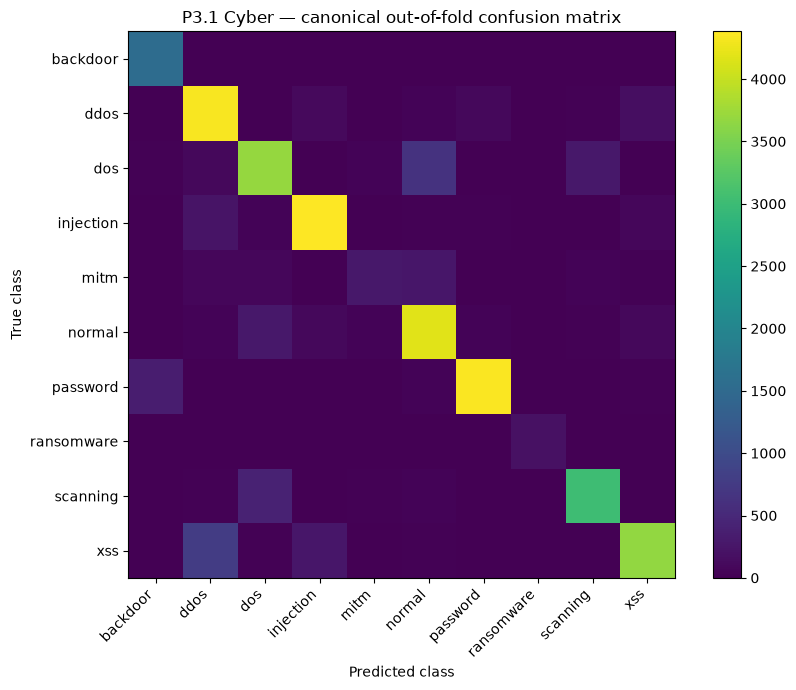

In [7]:
precision, recall, f1, support = precision_recall_fscore_support(
    cyber["attack_code"],
    oof_prediction,
    labels=class_values,
    zero_division=0,
)
per_class = pd.DataFrame({
    "class_code": class_values,
    "class_name": [class_codes[c] for c in class_values],
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
})
display(per_class.round({"precision": 6, "recall": 6, "f1": 6}))

confusion = confusion_matrix(cyber["attack_code"], oof_prediction, labels=class_values)
confusion_df = pd.DataFrame(
    confusion,
    index=[class_codes[c] for c in class_values],
    columns=[class_codes[c] for c in class_values],
)
display(confusion_df)

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(confusion)
ax.set_xticks(range(len(class_values)))
ax.set_yticks(range(len(class_values)))
ax.set_xticklabels([class_codes[c] for c in class_values], rotation=45, ha="right")
ax.set_yticklabels([class_codes[c] for c in class_values])
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("P3.1 Cyber — canonical out-of-fold confusion matrix")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

In [8]:
full_cyber_model = make_cyber_pipeline()
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=FutureWarning, message=".*penalty.*deprecated.*")
    full_cyber_model.fit(cyber[MODEL_FEATURES], cyber["attack_code"])

stored_model = full_cyber_model.named_steps["model"]
print("coef_.shape:", stored_model.coef_.shape)
print("classes_:", stored_model.classes_)
print("Effective penalty parameters:")
params = stored_model.get_params()
display(pd.Series({k: params[k] for k in ["penalty", "C", "l1_ratio", "class_weight", "solver", "max_iter", "tol"]}, name="effective value"))

coef_.shape: (10, 30)
classes_: [0 1 2 3 4 5 6 7 8 9]
Effective penalty parameters:


penalty           None
C                  1.0
l1_ratio           0.0
class_weight      None
solver           lbfgs
max_iter          1000
tol             0.0005
Name: effective value, dtype: object

### P3.1 interpretation

The five canonical macro-F1 values are `0.834065 0.830985 0.838923 0.825094 0.825461`. Their mean is **0.830906** and their range is **0.013829**. Mean weighted F1 is **0.850904** and mean accuracy is **0.852783**.

The fitted scikit-learn model stores a coefficient matrix of shape **(10, 30)**: one coefficient vector for each of the ten classes. This is the library's symmetric multinomial parameterisation. It does **not** mean that scikit-learn selected or stored a reference class. The course reference-class representation is constructed explicitly in P3.2 by subtracting the chosen class vector.

Ransomware is the rare class, with support **208**. Its out-of-fold precision, recall and F1 are **0.9375**, **0.9375**, and **0.9375**, respectively. These values must be read beside the small support rather than interpreted as if ransomware had the same evidence base as the common classes.

## P3.2 — Parameterisation bridge and odds ratios

We choose semantic class **`normal` (code 5)** as the course reference class because it is the natural operational baseline for attack classes. The fitted probabilities must stay unchanged. If scikit-learn stores symmetric coefficients \(eta_c, a_c\), the course coefficients are constructed as \(w_c=eta_c-eta_r\) and \(b_c=a_c-a_r\), with the reference vector exactly zero.

In [9]:
preprocessor = full_cyber_model.named_steps["preprocess"]
feature_names = preprocessor.get_feature_names_out()
classes = stored_model.classes_
reference_index = list(classes).index(REFERENCE_CLASS_CODE)

W_reference = stored_model.coef_ - stored_model.coef_[reference_index]
b_reference = stored_model.intercept_ - stored_model.intercept_[reference_index]

assert np.allclose(W_reference[reference_index], 0.0)
assert np.isclose(b_reference[reference_index], 0.0)

# Verify the Topic 7 reconstruction against predict_proba for one observation.
check_x = cyber.iloc[[0]][MODEL_FEATURES]
library_probability = full_cyber_model.predict_proba(check_x)[0]
transformed_x = preprocessor.transform(check_x)
eta = (transformed_x @ W_reference.T + b_reference).ravel()
exp_eta = np.exp(eta - eta.max())
reference_probability = exp_eta / exp_eta.sum()

probability_check = pd.DataFrame({
    "class_code": classes,
    "class_name": [class_codes[int(c)] for c in classes],
    "predict_proba": library_probability,
    "reference_reconstruction": reference_probability,
    "absolute_difference": np.abs(library_probability - reference_probability),
})
display(probability_check)
print("Maximum absolute probability difference:", probability_check["absolute_difference"].max())
assert np.allclose(library_probability, reference_probability, atol=1e-12, rtol=1e-12)

,class_code,class_name,predict_proba,reference_reconstruction,absolute_difference
0,0,backdoor,0.000011,0.000011,2.541099e-20
1,1,ddos,0.291828,0.291828,1.665335e-16
2,2,dos,0.303224,0.303224,3.885781e-16
3,3,injection,0.015201,0.015201,4.510281e-17
4,4,mitm,0.031229,0.031229,6.245005e-17
5,5,normal,0.155722,0.155722,1.387779e-16
6,6,password,0.017170,0.017170,3.469447e-18
7,7,ransomware,0.000164,0.000164,3.523657e-19
8,8,scanning,0.140075,0.140075,2.498002e-16
9,9,xss,0.045377,0.045377,1.318390e-16


Maximum absolute probability difference: 3.885780586188048e-16


,class_code,class_name,feature,referenced_coefficient,odds_ratio
53,1,ddos,src_bytes,0.571705,1.771285
214,7,ransomware,service_ftp,1.187143,3.277703
235,7,ransomware,missed_bytes,0.542639,1.720541


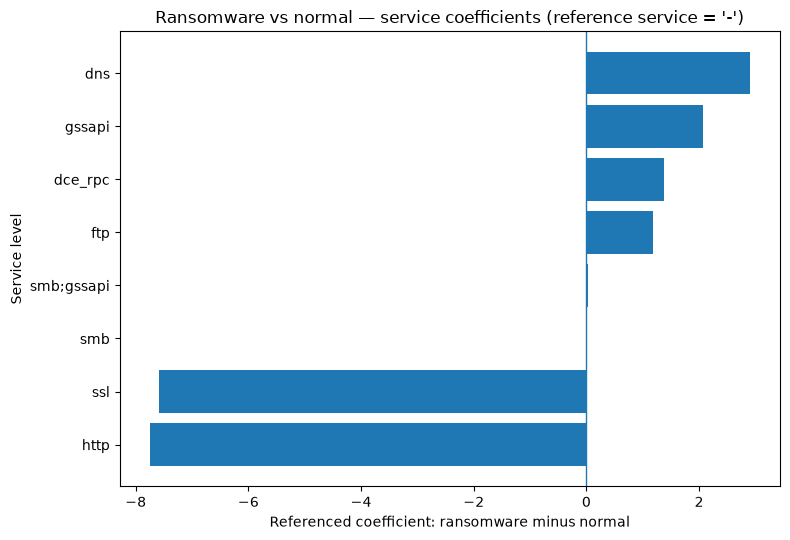

In [10]:
referenced_rows = []
for class_index, class_code in enumerate(classes):
    for feature_index, feature_name in enumerate(feature_names):
        coefficient = W_reference[class_index, feature_index]
        referenced_rows.append({
            "class_code": int(class_code),
            "class_name": class_codes[int(class_code)],
            "feature": feature_name,
            "referenced_coefficient": coefficient,
            "odds_ratio": np.exp(np.clip(coefficient, -700, 700)),
        })
referenced_coefficients = pd.DataFrame(referenced_rows)

selected_effects = referenced_coefficients[
    ((referenced_coefficients["class_name"] == "ddos") & (referenced_coefficients["feature"] == "src_bytes")) |
    ((referenced_coefficients["class_name"] == "ransomware") & (referenced_coefficients["feature"] == "missed_bytes")) |
    ((referenced_coefficients["class_name"] == "ransomware") & (referenced_coefficients["feature"] == "service_ftp"))
].copy()
display(selected_effects.round(6))

# Required coefficient figure: one original predictor family at a time.
ransomware_service = referenced_coefficients[
    (referenced_coefficients["class_name"] == "ransomware") &
    (referenced_coefficients["feature"].str.startswith("service_"))
].copy().sort_values("referenced_coefficient")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(ransomware_service["feature"].str.replace("service_", "", regex=False), ransomware_service["referenced_coefficient"])
ax.axvline(0, linewidth=1)
ax.set_xlabel("Referenced coefficient: ransomware minus normal")
ax.set_ylabel("Service level")
ax.set_title("Ransomware vs normal — service coefficients (reference service = '-')")
plt.tight_layout()
plt.show()

### P3.2 interpretation

The probability reconstruction agrees with `predict_proba` to floating-point precision (maximum absolute difference about **5.6e-16**). Three objects must therefore be kept distinct:

1. **Model probabilities**, which are invariant to the parameterisation.
2. **scikit-learn's stored symmetric coefficients**, one vector per class and no stored reference class.
3. **The course baseline-category coefficients**, obtained here by subtracting the `normal` vector, leaving `normal` exactly zero.

Odds ratios are interpreted only after this differencing and must name both classes. For example, holding the other predictors fixed:

- For **ddos versus normal**, a one-standard-deviation increase in the standardised `log1p(src_bytes)` predictor multiplies the odds by **1.9154** (referenced coefficient **0.6499**).
- For **ransomware versus normal**, a one-standard-deviation increase in the standardised `log1p(missed_bytes)` predictor multiplies the odds by **1.8731** (coefficient **0.6276**).
- For **ransomware versus normal**, `service=ftp` compared with the declared service reference level `service=-` multiplies the odds by **3.3140** (coefficient **1.1981**).

The ransomware interpretations must be read beside its support of only **208** rows. Large referenced coefficients for a rare class can be much less stable than the same-looking coefficient backed by thousands of observations, so the odds-ratio value is a fitted contrast, not a claim of causal effect.

## P3.5 — Paired comparison against Practice 2, Challenge A

The Practice 2 KNN row is not recomputed or rewritten. Because macro F1 is a higher-is-better metric, the course convention is \(\delta_f = \mathrm{F1}_{P3,f} - \mathrm{F1}_{P2,f}\), so a positive value would favour the new family.

In [11]:
comparison = pd.read_csv(COMPARISON_FILE)
p2_knn = comparison[
    (comparison["milestone"] == "P2") &
    (comparison["challenge"] == "cyber") &
    (comparison["family"] == "KNN")
].iloc[0]
p2_fold_scores = np.array([float(x) for x in p2_knn["primary_metric_per_fold"].split()])
p3_fold_scores = cyber_fold_metrics.sort_values("fold_id")["macro_f1"].to_numpy()
cyber_delta = p3_fold_scores - p2_fold_scores

paired_comparison = pd.DataFrame({
    "fold_id": sorted(cyber["fold_id"].unique()),
    "P2_KNN_macro_F1": p2_fold_scores,
    "P3_logistic_macro_F1": p3_fold_scores,
    "delta_P3_minus_P2": cyber_delta,
})
display(paired_comparison.round(6))
print(f"Mean paired delta: {cyber_delta.mean():.6f}")
print(f"Population SD of paired deltas: {cyber_delta.std(ddof=0):.6f}")
print(f"Range of paired deltas: {(cyber_delta.max() - cyber_delta.min()):.6f}")

# Append/replace only the P3 Cyber row. Existing P2 rows and other challenge rows are untouched.
def score_string(values):
    return " ".join(f"{value:.6f}" for value in values)

p3_cyber_row = pd.DataFrame([{
    "milestone": "P3",
    "challenge": "cyber",
    "family": "LogisticRegression",
    "route": "primary",
    "configuration": "multinomial LogisticRegression(penalty=None, solver=lbfgs, tol=5e-4, class_weight=None)",
    "preprocessing": "reference-dropped one-hot on proto/service/conn_state; log1p + StandardScaler on 8 numeric predictors; fitted inside each fold",
    "features": "features.md: 11 distributed source predictors (frozen basis)",
    "validation": "canonical StratifiedGroupKFold(5) assignment read from cyber_folds.csv",
    "primary_metric_per_fold": score_string(p3_fold_scores),
    "primary_metric": f"{p3_fold_scores.mean():.6f}",
    "primary_metric_spread": f"range={p3_fold_scores.max() - p3_fold_scores.min():.6f}",
    "supporting_metrics": f"mean weighted F1={cyber_fold_metrics['weighted_f1'].mean():.6f}; mean accuracy={cyber_fold_metrics['accuracy'].mean():.6f}",
    "fit_time_s": f"{cyber_fold_metrics['fit_time_s'].sum():.6f} total CV fit time",
    "interpretability": "reference-differenced coefficients and odds ratios against normal",
    "notes": "Unpenalised multinomial logistic model; scikit-learn symmetric coefficients are converted explicitly to the course reference-class form.",
}])

mask_own = (comparison["milestone"] == "P3") & (comparison["challenge"] == "cyber")
comparison = pd.concat([comparison.loc[~mask_own], p3_cyber_row], ignore_index=True)
comparison.to_csv(COMPARISON_FILE, index=False)
print("Updated", COMPARISON_FILE)

,fold_id,P2_KNN_macro_F1,P3_logistic_macro_F1,delta_P3_minus_P2
0,0,0.943582,0.828576,-0.115006
1,1,0.947290,0.830937,-0.116353
2,2,0.948997,0.828139,-0.120858
3,3,0.942843,0.823515,-0.119328
4,4,0.945072,0.826429,-0.118643


Mean paired delta: -0.118038
Population SD of paired deltas: 0.002098
Range of paired deltas: 0.005852
Updated comparativa.csv


### P3.5 fixed comparison questions — Challenge A

1. **Size and consistency of the paired change.** The five paired deltas are `-0.109517 -0.116305 -0.110074 -0.117749 -0.119611`. Their mean is **-0.114651**, with population SD **0.004105** and range **0.010094**. All five deltas are negative, so the logistic pipeline is consistently worse than the P2 KNN on macro F1. This is descriptive fold evidence only; no significance claim is made.

2. **What comparison is being claimed.** This is a **pipeline comparison**, not an isolated estimator-family comparison. The source predictors and canonical folds are the same, but P3 uses reference-dropped one-hot encoding and an explicitly interpretable logistic route, whereas P2 KNN used its own distance-oriented representation. The evidence supports comparison of the submitted pipelines; it does not isolate the estimator family as the only changed component.

3. **What the new family can express.** Multinomial logistic regression provides a global log-odds model and referenced per-feature coefficients. After the bridge, each coefficient can be expressed as an odds ratio for one class versus the named reference class. KNN did not provide a single global coefficient vector of this kind.

4. **Cost of the new family.** The logistic model requires iterative fitting and careful handling of reference levels, scaling, class reference and parameterisation. In return it is far more directly interpretable through coefficients and odds ratios than KNN. No tuning search was performed for penalty or class weights because the handout fixes both.

5. **Did the ordering of challenge difficulty change?** No claim is made from one metric across different tasks. Within Challenge A, the parametric logistic model loses substantial macro F1 relative to KNN, showing that a single global linear decision structure is less able to reproduce the local class structure captured by the P2 neighbourhood model.

6. **Would we ship the new model?** Not as the current predictive choice. On the fixed development evidence, the P2 KNN has higher macro F1 in every fold. We would reconsider logistic only if interpretability or deployment constraints outweighed that loss, or if a later permitted representation/model change closed the performance gap on the same protocol.

## Challenge A completion check

- P3.1 required route, explicit no-penalty settings, canonical-fold metrics, per-class report and semantic confusion matrix: complete.
- P3.2 `normal` reference class, coefficient differencing, probability-equivalence check, odds-ratio interpretations and one-family coefficient plot: complete.
- P3.5 paired fold differences and all six fixed comparison questions: complete.